In [1]:
### DATA EXPLOARTION

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print("Libraries imported successfully!")

Pandas version: 2.1.4
NumPy version: 1.26.4
Libraries imported successfully!


In [3]:
#Load the VM-level CPU readings
cpu_df = pd.read_csv("challenge_data/vm_cpu_readings.csv.gz")

#Load the metadata for each virtual machine
metadata_df = pd.read_csv("challenge_data/vm_metadata.csv.gz")

print(f"CPU readings shape: {cpu_df.shape}")
print(f"VM metadata shape: {metadata_df.shape}")

CPU readings shape: (1340000, 5)
VM metadata shape: (10000, 11)


In [4]:
cpu_df.head()

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [5]:
metadata_df.head()

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


In [6]:
cpu_df.columns.tolist()

['timestamp', 'vm_id', 'min_cpu', 'max_cpu', 'avg_cpu']

In [7]:
metadata_df.columns.tolist()

['vm_id',
 'subscription_id',
 'deployment_id',
 'timestamp_vm_created',
 'timestamp_vm_deleted',
 'max_cpu',
 'avg_cpu',
 'p95_max_cpu',
 'vm_category',
 'virtual_core_bucket',
 'memory_gb_bucket']

In [8]:
cpu_df.dtypes

timestamp      int64
vm_id         object
min_cpu      float64
max_cpu      float64
avg_cpu      float64
dtype: object

In [9]:
cpu_df.isnull().sum()

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

In [10]:
metadata_df.isnull().sum()

vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64

In [11]:
cpu_df.duplicated().sum()

0

In [12]:
metadata_df.duplicated().sum()

0

In [13]:
print(f"First 5 CPU records: {cpu_df.head().to_string(index=False)}")

First 5 CPU records:  timestamp                                                            vm_id  min_cpu   max_cpu  avg_cpu
         0 H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP8DJEdkl6fl+a5uWHxB 1.812194 14.587021 4.851659
         0 pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiWk0Hw8b5VSrGywwP4fY 4.126021  5.650850 4.687886
         0 iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+QvKWGIHb5Tjrh0ysxXj 1.225669  2.082111 1.607588
         0 /f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2FI27Lff2WvX5m15AN0b 1.939634  3.228830 2.374714
         0 wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUluH/qDXp7E+2c7+Pa48Y 0.352236  0.855003 0.597535


In [14]:
# to get all unique timestamps and sort them
timestamps = sorted(cpu_df["timestamp"].dropna().unique())
print(f"Number of unique timstamps: {len(timestamps)}")
print(f"{timestamps[:10]}")

Number of unique timstamps: 134
[0, 300, 600, 900, 1200, 1500, 1800, 2100, 2400, 2700]


In [15]:
#to calculate the diffrence between consecutive timestamps
timestamp_differences = pd.Series(timestamps).diff().dropna()
timestamp_differences.value_counts().sort_index()

300.0    133
Name: count, dtype: int64

In [16]:
#to check how many intervals equal 300 seconds
(timestamp_differences == 300).sum()

133

In [17]:
#to count how many CPU observations exist at each timestamp
observations_per_timestamp = cpu_df.groupby("timestamp").size()

observations_per_timestamp.describe()

print(f"Smallest number of observations at a timestamp:{observations_per_timestamp.min()}")

print(f"Largest number of observations at a timestamp: {observations_per_timestamp.max()}")

print(f"First 10 observation counts: {observations_per_timestamp.head(10)}")

Smallest number of observations at a timestamp:10000
Largest number of observations at a timestamp: 10000
First 10 observation counts: timestamp
0       10000
300     10000
600     10000
900     10000
1200    10000
1500    10000
1800    10000
2100    10000
2400    10000
2700    10000
dtype: int64


In [18]:
#to count unique VMs in each dataset
cpu_vm_count = cpu_df["vm_id"].nunique()
metadata_vm_count = metadata_df["vm_id"].nunique()

cpu_vm_count


10000

In [19]:
metadata_vm_count

10000

In [20]:
# Check whether each metadata VM has CPU readings
cpu_vm_ids = set(cpu_df["vm_id"].unique())
metadata_vm_ids = set(metadata_df["vm_id"].unique())

print(f"VMs in metadata without CPU readings: {len(metadata_vm_ids - cpu_vm_ids)}")

print(f"VMs with CPU readings but missing from metadata: {len(cpu_vm_ids - metadata_vm_ids)}")

VMs in metadata without CPU readings: 0
VMs with CPU readings but missing from metadata: 0


In [21]:
#to check for repeated records of the same VM at the same timestamp

duplicate_vm_readings_check = cpu_df.duplicated(subset = ["timestamp", "vm_id"]).sum()

print(f"Sum of duplicate VM-timestamp records: {duplicate_vm_readings_check}")

Sum of duplicate VM-timestamp records: 0


In [22]:
#to group all CPU readings by timestamp
aggregate_df = cpu_df.groupby("timestamp").agg(
    active_vm_count = ("vm_id", "nunique"),
    aggregate_cpu_utilization = ("avg_cpu", "mean")).reset_index()

print(aggregate_df.head())

#to check the size of the new dataset
print(f"Summary dataset: {aggregate_df.shape}")

   timestamp  active_vm_count  aggregate_cpu_utilization
0          0            10000                   9.396898
1        300            10000                   9.353775
2        600            10000                   9.454383
3        900            10000                   9.224419
4       1200            10000                   9.143503
Summary dataset: (134, 3)


In [23]:
#to ensure the summary table is in chronological order
aggregate_df = aggregate_df.sort_values("timestamp").reset_index(drop = True)

#to use the first 110 observations for traaining
train_df = aggregate_df.iloc[:110].copy()

#to reserve the final 24 observations for the final forecast
holdout_df = aggregate_df.iloc[110:].copy()

print(train_df.shape)
print(holdout_df.shape)

print(f"Training period: {train_df['timestamp'].iloc[0]} to {train_df['timestamp'].iloc[-1]}")

print(f"Holdout period: {holdout_df['timestamp'].iloc[0]} to {holdout_df['timestamp'].iloc[-1]}")

(110, 3)
(24, 3)
Training period: 0 to 32700
Holdout period: 33000 to 39900


### DATA VISUALIZATION

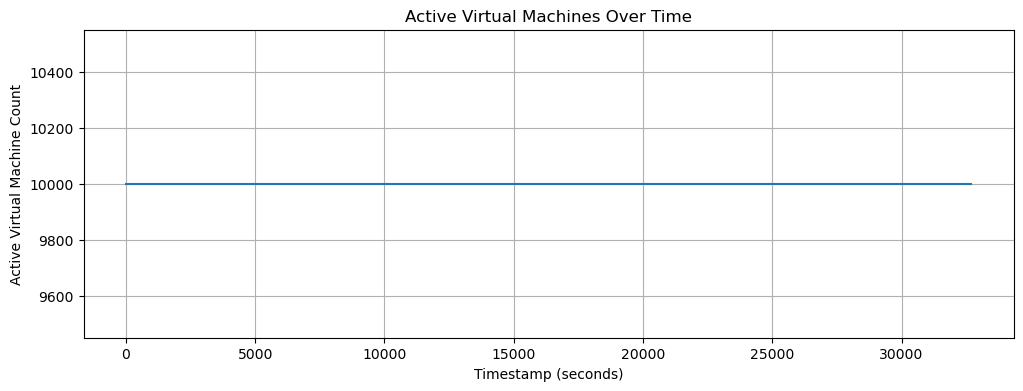

In [24]:
#to plot active VM count during the training period
plt.figure(figsize = (12, 4))
plt.plot(train_df["timestamp"], train_df["active_vm_count"])
plt.title("Active Virtual Machines Over Time")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Active Virtual Machine Count")
plt.grid(True)
plt.show()

### FIRST METHOD PERSISTENCE FORECASTING

In [25]:
# Persistence Method- using the most recents readings to predict the next readings

#using the first 90 obeservations as historical data
validation_history = train_df.iloc[:90].copy()

#then using the next 20 observations to validate our forecasts
validation_actual = train_df.iloc[90:].copy()

print(f'Historical data shape: {validation_history.shape}')
print(f'Validation data shape: {validation_actual.shape}')

print(f"Last historical timestamp: {validation_history['timestamp'].iloc[-1]}")
print(f"First validation timestamp: {validation_actual['timestamp'].iloc[0]}")

Historical data shape: (90, 3)
Validation data shape: (20, 3)
Last historical timestamp: 26700
First validation timestamp: 27000


In [26]:
#getting the most recent observed values
last_active_vm_count = validation_history["active_vm_count"].iloc[-1]
last_cpu_utilization = validation_history["aggregate_cpu_utilization"].iloc[-1]

#to create predictions for the 20 validation timestamp
persistence_predictions = pd.DataFrame({
    "timestamp" : validation_actual["timestamp"],
    "active_vm_count" : last_active_vm_count,
    "aggregate_cpu_utilization" : last_cpu_utilization
})
print(f"Number of predictions:{len(persistence_predictions)}")
#to display the first five predictions
persistence_predictions.head()

Number of predictions:20


,timestamp,active_vm_count,aggregate_cpu_utilization
90,27000,10000,9.393673
91,27300,10000,9.393673
92,27600,10000,9.393673
93,27900,10000,9.393673
94,28200,10000,9.393673


In [27]:
#comparing actual values with predicted values
for target in ["active_vm_count", "aggregate_cpu_utilization"]:
    actual = validation_actual[target]
    predicted = persistence_predictions[target]

    #calcuating MAE
    mae = mean_absolute_error(actual, predicted)

    #calculate RMSE
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print(f"Target: {target}")
    print(f"Mean Absolute Error: {mae:.4f}")
    print(f"Root Mean Square Error: {rmse:.4f}")

Target: active_vm_count
Mean Absolute Error: 0.0000
Root Mean Square Error: 0.0000
Target: aggregate_cpu_utilization
Mean Absolute Error: 0.1585
Root Mean Square Error: 0.1797


### SECOND METHOD MOVING AVERAGE

In [28]:
# using the last 6 historical observations
window_size = 6

#calculate the average active vm count
average_active_vm_count = (validation_history["active_vm_count"].tail(window_size).mean())

#calculate the average CPU utilization
average_cpu_utilization = (validation_history["aggregate_cpu_utilization"].tail(window_size).mean())

#Then creating moving-average predictions
moving_average_predictions = pd.DataFrame({
    "timestamp" : validation_actual["timestamp"],
    "active_vm_count" : average_active_vm_count,
    "aggregate_cpu_utilization" : average_cpu_utilization})


moving_average_predictions.head()

,timestamp,active_vm_count,aggregate_cpu_utilization
90,27000,10000.0,9.302357
91,27300,10000.0,9.302357
92,27600,10000.0,9.302357
93,27900,10000.0,9.302357
94,28200,10000.0,9.302357


In [29]:
for target in ["active_vm_count", "aggregate_cpu_utilization"]:
    actual = validation_actual[target]
    predicted = moving_average_predictions[target]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print(f"Target: {target}")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")



Target: active_vm_count
MAE: 0.0000
RMSE: 0.0000
Target: aggregate_cpu_utilization
MAE: 0.0977
RMSE: 0.1152


### SECOND VALIDATION WINDOW

In [30]:
# First 100 observations: historical data
validation_history_2 = train_df.iloc[:100].copy()

# Next 10 observations: validation data
validation_actual_2 = train_df.iloc[100:].copy()

print("Historical data shape:", validation_history_2.shape)
print("Validation data shape:", validation_actual_2.shape)

print("Last historical timestamp:",
      validation_history_2["timestamp"].iloc[-1])

print("First validation timestamp:",
      validation_actual_2["timestamp"].iloc[0])

Historical data shape: (100, 3)
Validation data shape: (10, 3)
Last historical timestamp: 29700
First validation timestamp: 30000


In [31]:
persistence_predictions_2 = pd.DataFrame({
    "timestamp": validation_actual_2["timestamp"],
    "active_vm_count": validation_history_2["active_vm_count"].iloc[-1],
    "aggregate_cpu_utilization": validation_history_2[
        "aggregate_cpu_utilization"
    ].iloc[-1]
})

persistence_predictions_2.head()

,timestamp,active_vm_count,aggregate_cpu_utilization
100,30000,10000,9.180825
101,30300,10000,9.180825
102,30600,10000,9.180825
103,30900,10000,9.180825
104,31200,10000,9.180825


In [32]:
window_size = 6

average_active_vm_count_2 = (
    validation_history_2["active_vm_count"].tail(window_size).mean()
)

average_cpu_utilization_2 = (
    validation_history_2["aggregate_cpu_utilization"].tail(window_size).mean()
)

moving_average_predictions_2 = pd.DataFrame({
    "timestamp": validation_actual_2["timestamp"],
    "active_vm_count": average_active_vm_count_2,
    "aggregate_cpu_utilization": average_cpu_utilization_2
})

moving_average_predictions_2.head()

,timestamp,active_vm_count,aggregate_cpu_utilization
100,30000,10000.0,9.274083
101,30300,10000.0,9.274083
102,30600,10000.0,9.274083
103,30900,10000.0,9.274083
104,31200,10000.0,9.274083


In [33]:
methods = {
    "Persistence": persistence_predictions_2,
    "Moving Average": moving_average_predictions_2
}

results_2 = []

for method_name, predictions in methods.items():
    for target in [
        "active_vm_count",
        "aggregate_cpu_utilization"
    ]:
        actual = validation_actual_2[target]
        predicted = predictions[target]

        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))

        results_2.append({
            "method": method_name,
            "target": target,
            "MAE": mae,
            "RMSE": rmse
        })

results_2_df = pd.DataFrame(results_2)
results_2_df

,method,target,MAE,RMSE
0,Persistence,active_vm_count,0.000000,0.000000
1,Persistence,aggregate_cpu_utilization,0.075945,0.100823
2,Moving Average,active_vm_count,0.000000,0.000000
3,Moving Average,aggregate_cpu_utilization,0.099074,0.115796


In [34]:
# Results from the first validation window
results_1 = pd.DataFrame([
    {
        "method": "Persistence",
        "target": "aggregate_cpu_utilization",
        "MAE": 0.1585,
        "RMSE": 0.1797
    },
    {
        "method": "Moving Average",
        "target": "aggregate_cpu_utilization",
        "MAE": 0.0977,
        "RMSE": 0.1152
    }
])

# Keep CPU results from the second validation window
results_2_cpu = results_2_df[
    results_2_df["target"] == "aggregate_cpu_utilization"
].copy()

# Combine the two sets of results
comparison = pd.concat(
    [results_1, results_2_cpu],
    ignore_index=True
)
comparison



,method,target,MAE,RMSE
0,Persistence,aggregate_cpu_utilization,0.158500,0.179700
1,Moving Average,aggregate_cpu_utilization,0.097700,0.115200
2,Persistence,aggregate_cpu_utilization,0.075945,0.100823
3,Moving Average,aggregate_cpu_utilization,0.099074,0.115796


In [35]:
# Compare average errors across the two windows
comparison_summary = comparison.groupby("method").agg({
    "MAE": "mean",
    "RMSE": "mean"
}).reset_index()

comparison_summary

,method,MAE,RMSE
0,Moving Average,0.098387,0.115498
1,Persistence,0.117223,0.140262


### EXAMINING THE WORKLOAD PATTERNS

#### 1. TREND

Trend- to check if the CPU utilization generally increase, decrease or stay around the same level.

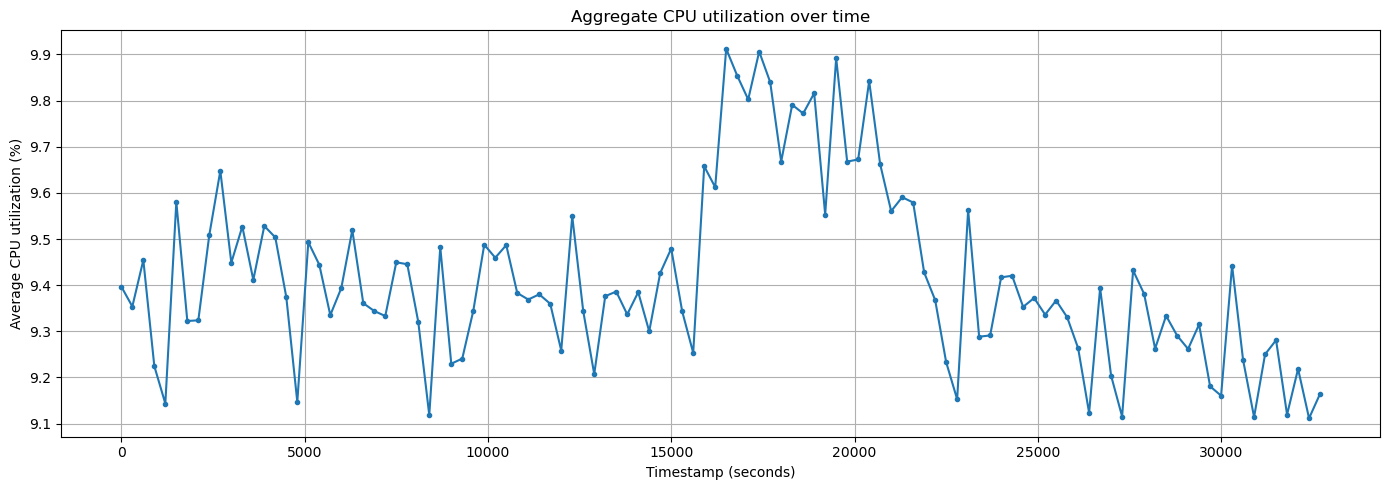

In [36]:
import matplotlib.pyplot as plt
plt.figure(figsize = (14, 5))
plt.plot(
    train_df["timestamp"],
    train_df["aggregate_cpu_utilization"],
    marker = "o",
    markersize = 3
)

plt.title("Aggregate CPU utilization over time")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Average CPU utilization (%)")

plt.grid(True)
plt.tight_layout()
plt.show()


In [37]:
train_df["aggregate_cpu_utilization"].describe()

count    110.000000
mean       9.414089
std        0.193568
min        9.111634
25%        9.288952
50%        9.378121
75%        9.507673
max        9.912175
Name: aggregate_cpu_utilization, dtype: float64

### Aggregate CPU Utilization Analysis

The development dataset contains 110 observations of aggregate CPU utilization, recorded at five-minute intervals.

The average aggregate CPU utilization was approximately 9.41%, with a standard deviation of 0.19 percentage points. Utilization ranged from 9.11% to 9.91%, indicating relatively low variation across the observation period.

The time-series plot shows fluctuations around the average utilization level, with a noticeable period of increased activity between approximately 16,000 and 21,000 seconds. Following this period, utilization declined and continued fluctuating at a slightly lower level.

These observations suggest that the workload is relatively stable at the aggregate level, although temporary increases in CPU demand occur. This makes it important to evaluate forecasting methods on their ability to capture both normal fluctuations and periods of increased demand.

In [38]:
#identifying the five highest CPU utilization observations

top_5_cpu = train_df.nlargest(5, "aggregate_cpu_utilization")
top_5_cpu

,timestamp,active_vm_count,aggregate_cpu_utilization
55,16500,10000,9.912175
58,17400,10000,9.906192
65,19500,10000,9.891946
56,16800,10000,9.853998
68,20400,10000,9.842210


In [39]:
#to check whether changes in the aggregate CPu utilization might be associated with changes in the number of running VMs
print(f"Active VM Count Summary: {train_df['active_vm_count'].describe()}")

print(f"Unique active VM counts: {train_df['active_vm_count'].unique()}")

Active VM Count Summary: count      110.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0
Name: active_vm_count, dtype: float64
Unique active VM counts: [10000]


Since the count remains at 10,000 throughout the development perio, it menas the active VM count has no varaiation for the forecasting task.

In [40]:
print(f"\nVM-level CPU Summary: {cpu_df['avg_cpu'].describe()}")

print(f"\nHighest indivisul VM average CPU readings: {cpu_df.nlargest(10, 'avg_cpu')[['timestamp', 'vm_id', 'avg_cpu']]}")


VM-level CPU Summary: count    1.340000e+06
mean     9.388101e+00
std      1.426601e+01
min      7.158922e-03
25%      2.477060e+00
50%      5.105133e+00
75%      9.616715e+00
max      9.948803e+01
Name: avg_cpu, dtype: float64

Highest indivisul VM average CPU readings:         timestamp                                              vm_id  \
150891       4500  EI9YhOIbD2e97NSgi3vsreRn7vOLIzyohlURl8xyT9cg9m...   
104881       3000  GzK9f4/XrpAbRzzFsqN3IKIr2lcoRGODm8f6m0AY6RpLJ4...   
14877         300  GzK9f4/XrpAbRzzFsqN3IKIr2lcoRGODm8f6m0AY6RpLJ4...   
908099      27000  dq8eqfbmQMQh33g+s/uwQb+AK6HlvnOXOvDscJhh80uV5k...   
878094      26100  dq8eqfbmQMQh33g+s/uwQb+AK6HlvnOXOvDscJhh80uV5k...   
898083      26700  dq8eqfbmQMQh33g+s/uwQb+AK6HlvnOXOvDscJhh80uV5k...   
658084      19500  dq8eqfbmQMQh33g+s/uwQb+AK6HlvnOXOvDscJhh80uV5k...   
918084      27300  dq8eqfbmQMQh33g+s/uwQb+AK6HlvnOXOvDscJhh80uV5k...   
738087      21900  dq8eqfbmQMQh33g+s/uwQb+AK6HlvnOXOvDscJhh80uV5k...   
598083 

For this, the mean is 9.39% and the median is 5.11%. This suggest that the CPU utilizartion is not evenly distributed across VMs. A relatively small number of VMs with high utilization may be pulling theoverall average upwards

In [41]:
peak_timestamp = top_5_cpu.iloc[0]["timestamp"]
peak_vm_readings = cpu_df[cpu_df["timestamp"] == peak_timestamp]
print(f"Peak timestamp: {peak_timestamp}")

print(f"{peak_vm_readings['avg_cpu'].describe()}")

Peak timestamp: 16500.0
count    10000.000000
mean         9.912175
std         14.851285
min          0.007176
25%          2.466739
50%          5.130465
75%         10.203987
max         99.242283
Name: avg_cpu, dtype: float64


Even when the overalll average is only 9.91%, at least one VM is operating at approximately 99% CPu utilization. This suggests that some VMs experience much heavier workloads than others. Therefore using only the aggregate CPU utilization alone to conclude that there is no risk of individual VM saturation is not possible.

In [42]:
# Keep only VM readings from the development period
development_cpu = cpu_df[cpu_df["timestamp"].isin(train_df["timestamp"])].copy()

# Count VMs above selected CPU thresholds at each timestamp
high_cpu_summary = pd.DataFrame({
    "VMs above 80%": development_cpu[development_cpu["avg_cpu"] > 80].groupby("timestamp")["vm_id"].nunique(),

    "VMs above 90%": development_cpu[development_cpu["avg_cpu"] > 90].groupby("timestamp")["vm_id"].nunique(),

    "VMs above 95%": development_cpu[development_cpu["avg_cpu"] > 95].groupby("timestamp")["vm_id"].nunique()
}).fillna(0).astype(int)

high_cpu_summary.describe()

,VMs above 80%,VMs above 90%,VMs above 95%
count,110.000000,110.000000,110.000000
mean,127.209091,87.836364,56.627273
std,6.755352,6.326770,5.315477
min,108.000000,73.000000,41.000000
25%,123.000000,84.000000,53.000000
50%,127.000000,87.500000,57.000000
75%,132.000000,92.000000,60.750000
max,146.000000,102.000000,67.000000


In [43]:
# Show the timestamps with the most VMs above 80% CPU
high_cpu_summary.sort_values("VMs above 80%",ascending=False).head(10)

,VMs above 80%,VMs above 90%,VMs above 95%
timestamp,,,
17400,146,100,55
19800,143,98,65
20100,143,98,67
19500,139,90,66
17700,137,93,56
18300,137,84,50
21000,137,92,60
18000,136,89,53
4200,136,90,61


Although aggregate CPU utilization remained relatively low, individual VM readings showed a more uneven distribution of workload. Across the 110 development timestamps, an average of approximately 127 VMs recorded CPU utilization above 80%, 88 exceeded 90%, and 57 exceeded 95%. The number of VMs above these thresholds increased during parts of the elevated aggregate CPU period, particularly between approximately 17,400 and 21,000 seconds. This indicates that aggregate CPU averages can conceal high utilization on individual VMs and should not be used alone to assess potential capacity pressure.

In [44]:
#Calculating rolling averages.
#A rolling average smooths short-term flunctuations. 

train_df["rolling_mean_30min"] = (train_df["aggregate_cpu_utilization"].rolling(window=6).mean())

train_df[["timestamp", "aggregate_cpu_utilization", "rolling_mean_30min"]].tail(15)

,timestamp,aggregate_cpu_utilization,rolling_mean_30min
95,28500,9.333663,9.288059
96,28800,9.290800,9.302558
97,29100,9.261760,9.326951
98,29400,9.314962,9.307461
99,29700,9.180825,9.274083
100,30000,9.160524,9.257089
101,30300,9.442585,9.275243
102,30600,9.237916,9.266429
103,30900,9.114320,9.241855
104,31200,9.250152,9.231054


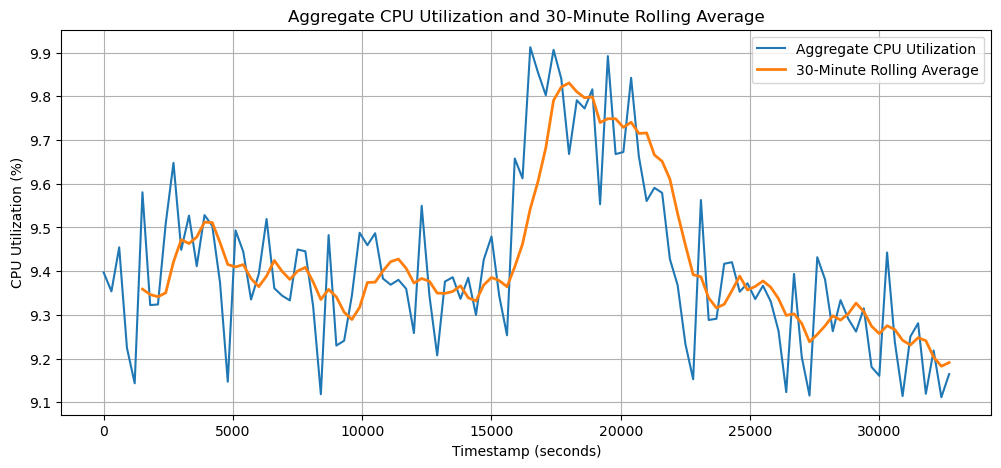

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(train_df["timestamp"],train_df["aggregate_cpu_utilization"],label="Aggregate CPU Utilization")
plt.plot(train_df["timestamp"],train_df["rolling_mean_30min"],label="30-Minute Rolling Average",linewidth=2)

plt.xlabel("Timestamp (seconds)")
plt.ylabel("CPU Utilization (%)")
plt.title("Aggregate CPU Utilization and 30-Minute Rolling Average")
plt.legend()
plt.grid(True)
plt.show()

### THIRD VALIDATION WINDOW

In [46]:
validation_results = []

for start in [80, 90, 100]:
    history = train_df.iloc[:start]
    actual = train_df.iloc[start:start + 10]

    #Persistence: repeat the last observed CPU value
    persistence_forecast = np.repeat(history["aggregate_cpu_utilization"].iloc[-1],len(actual))

    # Moving Average: use the average of the last 6 observations
    moving_average_forecast = np.repeat(history["aggregate_cpu_utilization"].tail(6).mean(),len(actual))
    actual_values = actual["aggregate_cpu_utilization"].to_numpy()

    # Calculate errors for Persistence
    persistence_errors = actual_values - persistence_forecast

    validation_results.append({
        "window": start,
        "method": "Persistence",
        "MAE": np.mean(np.abs(persistence_errors)),
        "RMSE": np.sqrt(np.mean(persistence_errors ** 2))
    })

    # Calculate errors for Moving Average
    moving_average_errors = actual_values - moving_average_forecast

    validation_results.append({
        "window": start,
        "method": "Moving Average",
        "MAE": np.mean(np.abs(moving_average_errors)),
        "RMSE": np.sqrt(np.mean(moving_average_errors ** 2))
    })

validation_results_df = pd.DataFrame(validation_results)

validation_results_df

,window,method,MAE,RMSE
0,80,Persistence,0.085660,0.095800
1,80,Moving Average,0.070720,0.086470
2,90,Persistence,0.123649,0.146765
3,90,Moving Average,0.075126,0.093235
4,100,Persistence,0.075945,0.100823
5,100,Moving Average,0.099074,0.115796


In [47]:
validation_summary = (validation_results_df.groupby("method")[["MAE", "RMSE"]].mean().reset_index())

validation_summary

,method,MAE,RMSE
0,Moving Average,0.081640,0.098500
1,Persistence,0.095084,0.114463


#### FORECAST ERROR ANALYSIS.

In [48]:
error_analysis = []

for start in [80, 90, 100]:

    history = train_df.iloc[:start]
    actual = train_df.iloc[start:start + 10]

    actual_values = actual["aggregate_cpu_utilization"].to_numpy()

    persistence_forecast = np.repeat(history["aggregate_cpu_utilization"].iloc[-1],len(actual))

    moving_average_forecast = np.repeat(history["aggregate_cpu_utilization"].tail(6).mean(),len(actual))

    for i in range(len(actual)):

        error_analysis.append({
            "window": start,
            "timestamp": actual.iloc[i]["timestamp"],
            "actual_cpu": actual_values[i],
            "persistence_prediction": persistence_forecast[i],
            "moving_average_prediction": moving_average_forecast[i],
            "persistence_error": (
                actual_values[i] - persistence_forecast[i]
            ),
            "moving_average_error": (
                actual_values[i] - moving_average_forecast[i]
            )
        })

error_analysis_df = pd.DataFrame(error_analysis)

error_analysis_df.head(5)

,window,timestamp,actual_cpu,persistence_prediction,moving_average_prediction,persistence_error,moving_average_error
0,80,24000.0,9.416892,9.291072,9.315971,0.125820,0.100920
1,80,24300.0,9.420464,9.291072,9.315971,0.129393,0.104493
2,80,24600.0,9.352936,9.291072,9.315971,0.061864,0.036964
3,80,24900.0,9.372250,9.291072,9.315971,0.081178,0.056278
4,80,25200.0,9.336187,9.291072,9.315971,0.045116,0.020216


In [49]:
error_analysis_df["absolute_moving_average_error"] = (error_analysis_df["moving_average_error"].abs())
worst_predictions = error_analysis_df.nlargest(10, "absolute_moving_average_error")
worst_predictions

,window,timestamp,actual_cpu,persistence_prediction,moving_average_prediction,persistence_error,moving_average_error,absolute_moving_average_error
8,80,26400.0,9.123236,9.291072,9.315971,-0.167835,-0.192735,0.192735
11,90,27300.0,9.115401,9.393673,9.302357,-0.278273,-0.186957,0.186957
21,100,30300.0,9.442585,9.180825,9.274083,0.261761,0.168503,0.168503
28,100,32400.0,9.111634,9.180825,9.274083,-0.069191,-0.162449,0.162449
23,100,30900.0,9.114320,9.180825,9.274083,-0.066505,-0.159763,0.159763
26,100,31800.0,9.119565,9.180825,9.274083,-0.061259,-0.154518,0.154518
12,90,27600.0,9.431903,9.393673,9.302357,0.038230,0.129546,0.129546
19,90,29700.0,9.180825,9.393673,9.302357,-0.212848,-0.121533,0.121533
20,100,30000.0,9.160524,9.180825,9.274083,-0.020301,-0.113559,0.113559
29,100,32700.0,9.164556,9.180825,9.274083,-0.016268,-0.109527,0.109527


In [50]:
pooled_metrics = pd.DataFrame({
    "method": ["Persistence", "Moving Average"],
    "MAE": [
        error_analysis_df["persistence_error"].abs().mean(),
        error_analysis_df["moving_average_error"].abs().mean()
    ],
    "RMSE": [
        np.sqrt((error_analysis_df["persistence_error"] ** 2).mean()),
        np.sqrt((error_analysis_df["moving_average_error"] ** 2).mean())
    ]
})

pooled_metrics

,method,MAE,RMSE
0,Persistence,0.095084,0.116737
1,Moving Average,0.081640,0.099295


### GENERATING PREDICTIONS.

In [51]:
#getting the final 6 development observations
last_6_cpu = train_df["aggregate_cpu_utilization"].tail(6)

#Forecast active VM count using persistence
predicted_active_vm_count = train_df["active_vm_count"].iloc[-1]

#forecase CPU utilization using moving average
predicted_cpu_utilization = last_6_cpu.mean()

#final predictions
predictions_df = pd.DataFrame({
    "timestamp" : holdout_df["timestamp"].values,
    "active_vm_count" : predicted_active_vm_count,
    "aggregate_cpu_utilization" : predicted_cpu_utilization
    
})

predictions_df

,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.190884
1,33300,10000,9.190884
2,33600,10000,9.190884
3,33900,10000,9.190884
4,34200,10000,9.190884
5,34500,10000,9.190884
6,34800,10000,9.190884
7,35100,10000,9.190884
8,35400,10000,9.190884
9,35700,10000,9.190884


In [53]:
#actual values from the holdout period
actual_cpu = holdout_df["aggregate_cpu_utilization"]

#predicted values
predicted_cpu = predictions_df["aggregate_cpu_utilization"]

#calculate evaluation metrics
holdout_mae = mean_absolute_error(actual_cpu, predicted_cpu)
holdout_rmse = np.sqrt(mean_squared_error(actual_cpu, predicted_cpu))

print(f"Holdout MAE: {holdout_mae:.6f}")
print(f"Holdout RMSE: {holdout_rmse:.6f}")

Holdout MAE: 0.133565
Holdout RMSE: 0.171289


In [54]:
# Calculate forecast errors
holdout_errors = actual_cpu.to_numpy() - predicted_cpu.to_numpy()

print(f"Mean forecast error: {holdout_errors.mean()}")
print(f"Average actual CPU utilization: {actual_cpu.mean()}")
print(f"Average predicted CPU utilization: {predicted_cpu.mean()}")

Mean forecast error: 0.07810402825558516
Average actual CPU utilization: 9.268987733051413
Average predicted CPU utilization: 9.190883704795828


In [55]:
active_vm_mae = mean_absolute_error(holdout_df["active_vm_count"], predictions_df["active_vm_count"])
active_vm_rmse = np.sqrt(mean_squared_error(holdout_df["active_vm_count"],predictions_df["active_vm_count"]))

print(f"Active VM Count MAE: {active_vm_mae}")
print(f"Active VM Count RMSE: {active_vm_rmse}")

Active VM Count MAE: 0.0
Active VM Count RMSE: 0.0


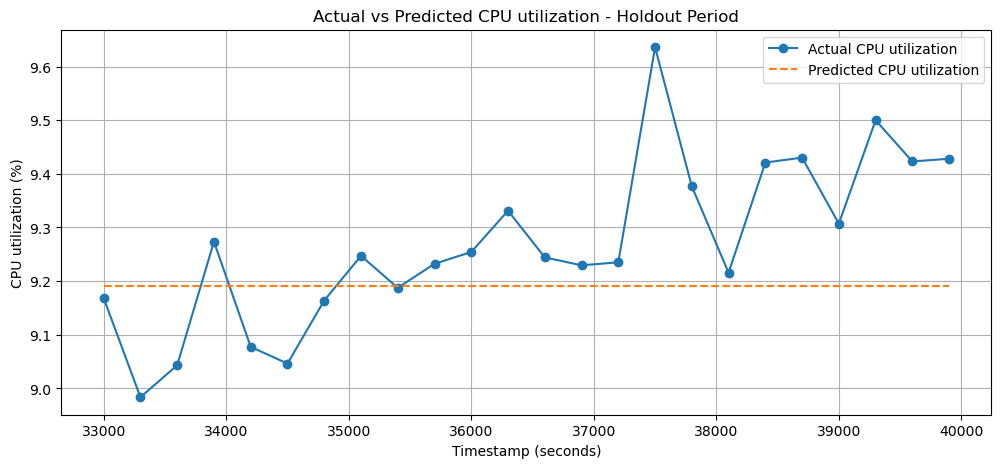

In [56]:
plt.figure(figsize = (12, 5))

plt.plot(holdout_df["timestamp"],
        actual_cpu,
        marker = "o",
        label = "Actual CPU utilization")

plt.plot(holdout_df["timestamp"],
        predicted_cpu,
        linestyle = "--",
        label = "Predicted CPU utilization"
        )

plt.xlabel("Timestamp (seconds)")
plt.ylabel("CPU utilization (%)")
plt.title("Actual vs Predicted CPU utilization - Holdout Period")
plt.legend()
plt.grid(True)
plt.show()

### Testing Simple Exponential Smoothing (SES) method using the three validations windows

In [57]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [58]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

In [59]:
ses_results = []

for start in [80, 90, 100]:

    # Historical observations
    history = train_df.iloc[:start]

    # Actual validation observations
    actual = train_df.iloc[start:start + 10]

    # Fit SES using historical CPU observations only
    ses_model = SimpleExpSmoothing(history["aggregate_cpu_utilization"],initialization_method="estimated")

    ses_fitted = ses_model.fit(optimized=True)

    # Forecast the next 10 observations
    ses_forecast = ses_fitted.forecast(len(actual))

    # Calculate errors
    actual_values = actual["aggregate_cpu_utilization"].to_numpy()
    errors = actual_values - ses_forecast.to_numpy()

    ses_results.append({
        "window": start,
        "alpha": ses_fitted.params["smoothing_level"],
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })

ses_results_df = pd.DataFrame(ses_results)

ses_results_df

,window,alpha,MAE,RMSE
0,80,0.430962,0.065456,0.084696
1,90,0.421265,0.074777,0.092788
2,100,0.409647,0.084886,0.104596


In [60]:
ses_summary = (ses_results_df[["MAE", "RMSE"]].mean().to_frame().T)
ses_summary.insert(0, "method", "Simple Exponential Smoothing")

all_methods_comparison = pd.concat([validation_summary,ses_summary],ignore_index=True)

all_methods_comparison.sort_values("MAE").reset_index(drop=True)

,method,MAE,RMSE
0,Simple Exponential Smoothing,0.075040,0.094027
1,Moving Average,0.081640,0.098500
2,Persistence,0.095084,0.114463


In [61]:
pooled_validation_errors = {
    "Persistence": [],
    "Moving Average": [],
    "Simple Exponential Smoothing": []
}

for start in [80, 90, 100]:

    history = train_df.iloc[:start]
    actual = train_df.iloc[start:start + 10]

    actual_values = actual["aggregate_cpu_utilization"].to_numpy()

    # Persistence
    persistence_forecast = np.repeat(history["aggregate_cpu_utilization"].iloc[-1], len(actual))

    # Moving Average
    moving_average_forecast = np.repeat(history["aggregate_cpu_utilization"].tail(6).mean(), len(actual))

    # Simple Exponential Smoothing
    ses_model = SimpleExpSmoothing(history["aggregate_cpu_utilization"], initialization_method="estimated")

    ses_fitted = ses_model.fit(optimized=True)
    ses_forecast = ses_fitted.forecast(len(actual)).to_numpy()

    # Store all forecast errors
    pooled_validation_errors["Persistence"].extend(actual_values - persistence_forecast)

    pooled_validation_errors["Moving Average"].extend(actual_values - moving_average_forecast)

    pooled_validation_errors["Simple Exponential Smoothing"].extend(actual_values - ses_forecast)

# Calculate pooled metrics
pooled_comparison = []

for method, errors in pooled_validation_errors.items():

    errors = np.array(errors)

    pooled_comparison.append({
        "Method": method,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })

pooled_comparison_df = pd.DataFrame(pooled_comparison)

pooled_comparison_df.sort_values("MAE").reset_index(drop=True)

,Method,MAE,RMSE
0,Simple Exponential Smoothing,0.075040,0.094381
1,Moving Average,0.081640,0.099295
2,Persistence,0.095084,0.116737


In [62]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Fit SES using all development observations
final_ses_model = SimpleExpSmoothing(train_df["aggregate_cpu_utilization"],initialization_method="estimated")

final_ses_fitted = final_ses_model.fit(optimized=True)

# Forecast the next 24 observations
final_cpu_forecast = final_ses_fitted.forecast(24)

# Forecast active VM count using Persistence
final_active_vm_forecast = train_df["active_vm_count"].iloc[-1]

# Create final predictions
predictions_df = pd.DataFrame({
    "timestamp": holdout_df["timestamp"].values,
    "active_vm_count": final_active_vm_forecast,
    "aggregate_cpu_utilization": final_cpu_forecast.to_numpy()
})

print(f"Selected SES alpha: {final_ses_fitted.params['smoothing_level']}")

predictions_df

Selected SES alpha: 0.3964148237880561


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.166976
1,33300,10000,9.166976
2,33600,10000,9.166976
3,33900,10000,9.166976
4,34200,10000,9.166976
5,34500,10000,9.166976
6,34800,10000,9.166976
7,35100,10000,9.166976
8,35400,10000,9.166976
9,35700,10000,9.166976


In [63]:
actual_cpu = holdout_df["aggregate_cpu_utilization"]
predicted_cpu = predictions_df["aggregate_cpu_utilization"]

ses_holdout_mae = mean_absolute_error(actual_cpu, predicted_cpu)

ses_holdout_rmse = np.sqrt(mean_squared_error(actual_cpu, predicted_cpu))

ses_holdout_error = (actual_cpu.to_numpy() - predicted_cpu.to_numpy())

print(f"SES Holdout MAE: {ses_holdout_mae:.6f}")
print(f"SES Holdout RMSE: {ses_holdout_rmse:.6f}")
print(f"Mean Forecast Error: {ses_holdout_error.mean():.6f}")

SES Holdout MAE: 0.145371
SES Holdout RMSE: 0.183428
Mean Forecast Error: 0.102011


Simple Exponential Smoothing achieved the lowest validation error, with an MAE of 0.075040 and RMSE of 0.094381. However, its holdout performance was weaker than that of the six-observation Moving Average. Moving Average achieved a holdout MAE of 0.133565 and RMSE of 0.171289, compared with 0.145371 and 0.183428 for Simple Exponential Smoothing. This indicates that the validation ranking did not fully generalize to the holdout period. Moving Average was retained as the final forecasting method based on its better observed holdout performance, while acknowledging the use of holdout results in this comparative decision.

In [64]:
# Forecast active VM count using the last observed value
predicted_active_vm_count = train_df["active_vm_count"].iloc[-1]

# Forecast CPU utilization using the average of the last 6 observations
predicted_cpu_utilization = train_df[
    "aggregate_cpu_utilization"
].tail(6).mean()

# Create forecasts for the 24 holdout timestamps
predictions_df = pd.DataFrame({
    "timestamp": holdout_df["timestamp"].values,
    "active_vm_count": predicted_active_vm_count,
    "aggregate_cpu_utilization": predicted_cpu_utilization
})

# Save without an index column
predictions_df.to_csv("predictions.csv", index=False)

# Validate the output
assert len(predictions_df) == 24
assert list(predictions_df.columns) == [
    "timestamp",
    "active_vm_count",
    "aggregate_cpu_utilization"
]
assert np.array_equal(predictions_df["timestamp"].values, holdout_df["timestamp"].values)
assert np.isfinite(predictions_df.select_dtypes(include="number")).all().all()
assert (predictions_df["active_vm_count"] >= 0).all()
assert predictions_df["aggregate_cpu_utilization"].between(0, 100).all()

print("predictions.csv created and validated successfully!")
display(predictions_df.head())

predictions.csv created and validated successfully!


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.190884
1,33300,10000,9.190884
2,33600,10000,9.190884
3,33900,10000,9.190884
4,34200,10000,9.190884


In [65]:
print("Predictions timestamps:")
print(predictions_df["timestamp"].head())
print(predictions_df["timestamp"].dtype)

print("\nHoldout timestamps:")
print(holdout_df["timestamp"].head())
print(holdout_df["timestamp"].dtype)

print("\nPredictions last timestamp:")
print(predictions_df["timestamp"].tail())

print("\nHoldout last timestamp:")
print(holdout_df["timestamp"].tail())

Predictions timestamps:
0    33000
1    33300
2    33600
3    33900
4    34200
Name: timestamp, dtype: int64
int64

Holdout timestamps:
110    33000
111    33300
112    33600
113    33900
114    34200
Name: timestamp, dtype: int64
int64

Predictions last timestamp:
19    38700
20    39000
21    39300
22    39600
23    39900
Name: timestamp, dtype: int64

Holdout last timestamp:
129    38700
130    39000
131    39300
132    39600
133    39900
Name: timestamp, dtype: int64


In [67]:
from pathlib import Path

forecast_code = '''import numpy as np
import pandas as pd
from pathlib import Path


def main():
    # Locate the project directory
    project_dir = Path(__file__).resolve().parent.parent

    # Load the source datasets
    cpu_path = project_dir / "challenge_data" / "vm_cpu_readings.csv.gz"
    metadata_path = project_dir / "challenge_data" / "vm_metadata.csv.gz"

    cpu_df = pd.read_csv(cpu_path)
    metadata_df = pd.read_csv(metadata_path)

    # Aggregate VM readings by timestamp
    aggregate_df = (
        cpu_df.groupby("timestamp")
        .agg(
            active_vm_count=("vm_id", "nunique"),
            aggregate_cpu_utilization=("avg_cpu", "mean")
        )
        .reset_index()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # Split development and holdout observations
    train_df = aggregate_df.iloc[:110].copy()
    holdout_df = aggregate_df.iloc[110:].copy()

    if len(train_df) != 110 or len(holdout_df) != 24:
        raise ValueError("Expected 110 development and 24 holdout observations.")

    # Forecast active VM count using the last observed value
    predicted_active_vm_count = train_df["active_vm_count"].iloc[-1]

    # Forecast CPU utilization using the last 6 observations
    predicted_cpu_utilization = (
        train_df["aggregate_cpu_utilization"].tail(6).mean()
    )

    # Generate forecasts for the holdout timestamps
    predictions_df = pd.DataFrame({
        "timestamp": holdout_df["timestamp"].values,
        "active_vm_count": predicted_active_vm_count,
        "aggregate_cpu_utilization": predicted_cpu_utilization
    })

    # Validate predictions
    assert len(predictions_df) == 24
    assert list(predictions_df.columns) == [
        "timestamp",
        "active_vm_count",
        "aggregate_cpu_utilization"
    ]
    assert np.array_equal(
        predictions_df["timestamp"].values,
        holdout_df["timestamp"].values
    )
    assert np.isfinite(
        predictions_df.select_dtypes(include="number")
    ).all().all()
    assert (predictions_df["active_vm_count"] >= 0).all()
    assert predictions_df["aggregate_cpu_utilization"].between(0, 100).all()

    # Save predictions
    output_path = project_dir / "predictions.csv"
    predictions_df.to_csv(output_path, index=False)

    print("Forecasting completed successfully!")
    print(f"Predictions saved to: {output_path}")
    print(predictions_df.head())


if __name__ == "__main__":
    main()
'''

Path("src/forecast.py").write_text(forecast_code, encoding="utf-8")

print("forecast.py created successfully!")
print(Path("src/forecast.py").exists())

forecast.py created successfully!
True


In [68]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "src/forecast.py"],
    capture_output=True,
    text=True
)

print("Output:")
print(result.stdout)

if result.returncode != 0:
    print("Error:")
    print(result.stderr)
else:
    print("Script executed successfully!")

Output:
Forecasting completed successfully!
Predictions saved to: C:\Users\Zibah\Documents\cloud-workload-forecasting\predictions.csv
   timestamp  active_vm_count  aggregate_cpu_utilization
0      33000            10000                   9.190884
1      33300            10000                   9.190884
2      33600            10000                   9.190884
3      33900            10000                   9.190884
4      34200            10000                   9.190884

Script executed successfully!


In [69]:
requirements = """numpy
pandas
matplotlib
scikit-learn
statsmodels
jupyter
"""

Path("requiremets.txt").write_text(requirements, encoding = "utf-8")

print("requiremets.txt created succesfully")

requiremets.txt created succesfully


In [70]:
from pathlib import Path

readme_content = """# Cloud Workload Forecasting & Analysis

## Project Overview

This project analyses historical cloud virtual machine (VM) CPU utilization and forecasts future workload behaviour using time-series forecasting techniques.

The goal is to estimate:
- The number of active virtual machines.
- Aggregate CPU utilization.

## Dataset

The project uses a curated subset of Azure Public Dataset V2.

- 10,000 virtual machines.
- 134 observations per VM.
- 5-minute observation intervals.
- 1,340,000 VM-level CPU records.

## Methodology

1. Data loading and quality checks.
2. Aggregation of VM-level CPU readings by timestamp.
3. Exploratory data analysis.
4. Chronological development and holdout split.
5. Time-aware validation and baseline comparison.
6. Forecast generation and evaluation.

The first 110 timestamps are used for development, while the final 24 timestamps form the forecast horizon.

## Forecasting Methods

The following methods were compared:

- Persistence forecasting.
- 30-minute moving average.
- Simple Exponential Smoothing.

The final forecasting implementation uses:
- Persistence for active VM count.
- A 30-minute moving average for aggregate CPU utilization.


## Project Structure

```text
cloud-workload-forecasting/
├── challenge_data/
├── notebooks/
│   └── 01_data_understanding.ipynb
├── src/
│   └── forecast.py
├── predictions.csv
├── requirements.txt
└── README.md
"""
Path("README.md").write_text(readme_content, encoding="utf-8")

print("README.md created successfully!")

README.md created successfully!


In [71]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [72]:
from pathlib import Path

report_content = """# Cloud Workload Forecasting and Analysis

## 1. 
Summary

This project studies cloud machine CPU usage by using a selected part of the Azure Public Dataset V2.

The goal is to learn about usage and predict the number of active virtual machines and overall CPU usage for the next two hours.

The data has 1,340,000 CPU readings from 10,000 machines at 134 different times. These times are five minutes apart.

Three ways to predict were tested: using the value a 30-minute average and a simple exponential smoothing method.

The final version uses the value for active VM count and the 30-minute average for overall CPU usage.

## 2. Dataset Understanding and Preparation

### 2.1 Dataset Description

The project uses two source files:

- vm_cpu_readings.csv.gz: CPU usage data for each machine.

- vm_metadata.csv.gz: Information about each virtual machine.

The CPU data has 1,340,000 rows and five columns. The metadata data has 10,000 rows and eleven columns.

Each virtual machine has 134 CPU readings with timestamp that is 300 seconds (5 minutes) apart.

### 2.2 Data Quality Checks

The following checks were done:

- Checked for missing values.

- Checked for duplicated records.

- Made sure the number of unique times was correct.

- Checked that the time difference was five minutes.

- Checked for duplicate virtual machine and time combinations.

- Compared the machine IDs in both datasets.

No missing data or duplicates were found. All 10,000 virtual machine IDs in the CPU dataset matched the metadata records.

### 2.3 Construction of the Target Variable 

The data was grouped by time to create two target variables:

**Active VM Count:** The number of distinct virtual machines with a CPU reading at each timestamp.

**Aggregate CPU Utilization:** The average of CPU readings for all machines at each timestamp.

The final data has 134 observations.

The active VM count remained constant at 10,000 during the time period.

## 3. Exploratory Data Analysis

### 3.1 Aggregate CPU Utilization

The development period had 110 observations.

Statistics for CPU usage were:

| Statistic | Value |
|---|---:|
| Mean | 9.4141% |
Standard deviation | 0.1936 |
| Minimum | 9.1116% |
| Median | 9.3781% |
| Maximum | 9.9122%

The CPU usage was mostly around 9.4%.

There was an increase around timestamp 16,500 to 21,000 seconds then it declined.

No clear repeating pattern was found in the available data.

### 3.2 VM-Level Utilization and High-Load Analysis

Even though overall CPU utilization was low,  individual VMs readings showed a wider distribution.

In the dataset the highest average CPU usage for a single VM was about 99.95%.

In the development period:

- On average, 127 VMs recorded CPU utilization above 80%.

- On average 88 VMs recorded CPU utilization above 90%.

- On average 57 VMs recorded CPU utilization above 95%.

The most VMs above 80% was 146 at timestamp 17,400 seconds.

This shows that low overall CPU usage does not mean all VMs have sufficient headroom.

## 4. Forecasting Methodology

### 4.1 Chronological Data Split

The 134 aggregate observations were split into:

- Development period: 110 observations.

- Holdout period: final 24 observations.

The holdout period is two hours because each observation is five minutes apart.

### 4.2 Forecasting Approaches

Three methods were compared.

**Persistence Forecasting**

This method uses the observed value as the forecast for future predictions.

It was used for active VM count since the count stayed at 10,000.

**30-Minute Moving Average**

This method calculates the mean of the six recent observations and uses it to predict CPU utilization for the next 24 steps.

**Simple Exponential Smoothing**

This method assigns greater weight to recent data while keeping information from earlier data.

### 4.3 Time-Aware Validation

Three expanding window tests were done:

- First window: 80 historical observations, followed by 10 validation observations.

- Second window: 90 historical observations, followed by 10 validation observations.

- Third window: 100 historical observations, followed by 10 validation observations.

The evaluation metrics used were Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Lower values indicates better forecast accuracy.

### 4.4 Validation Results

The results from 30 validation observations were:

| Forecasting Method | MAE | RMSE |
|---|---:|---:|
| Persistence | 0.095084 0.116737 |
| 30-Minute Moving Average | 0.081640 | 0.099295 |
| Simple Exponential Smoothing | 0.075040 | 0.094381 |

Simple Exponential Smoothing had the lowest validation errors.

Compared to persistence SES had 21.1% lower MAE and 19.2% lower RMSE.

The moving average also did better than persistence with 14.1% lower MAE and 15.0% lower RMSE.

### 4.5 Holdout Forecast Evaluation

The final implementation used persistence for VM count and the 30-minute moving average for aggregate CPU utilization.

The moving average forecast produced:

| Metric | Result |
|---|---:|
| CPU MAE | 0.133565 |
| CPU RMSE | 0.171289 |
| CPU NRMSE | 1.85% |
| Active VM Count MAE 0 |
Active VM Count RMSE | 0 |

The actual mean aggregate CPU utilization during the holdout period was approximately 9.2690% while the forecast average was about 9.1909%.

The positive error of about 0.0781 percentage points shows the moving average slightly underestimated the aggregate CPU utilization.

Even though SES did best during validation, the moving average had lower errors in the holdout comparison:

- Moving Average MAE: 0.133565; RMSE: 0.171289.

- SES MAE: 0.145371; RMSE: 0.183428.

**Evaluation limitation:** Both methods were compared after their forecasts were made.

## 5. Operational Analysis and Recommendations

### 5.1 Capacity and Headroom

The overall CPU utilization was low, averaging about 9.4% during the development period.

However, VM-level analysis showed that some machines redorded utilizaton above 90% and 95%

Recommended operational actions are:

1. Watch CPU utilization at each individual VM level.

2. Set up alerts for sustained high CPU utilization.

3. Look into machines taht repeatedly records utilization above 80%.

4. Check workload distribution and find issues with resources.

5. Maintain appropriate capacity headroom based on individual VM behaviour and service requirements.

A fixed capacity reduction is not recommended from aggregate CPU averages alone.

### 5.2 Forecasting Improvements

Possible future improvements include:

- Use longer data to check for daily or weekly patterns.

- Forcasting individual VM workloads or workload groups.

## 6. Limitations

The analysis has some issues:

- The development period is nine hours, which is not enough to see longer patterns.

- The moving average produces a constant forecast across the 24-steps.

- Aggregate CPU utilization can hide high utilization on individual virtual machines.

- The dataset is a selected part and may not show all behaviors in a real cloud.

- The post-hoc holdout comparison is not an independent final model-selection assessment.

## 7. Conclusion

This project shows a way to study cloud workloads and predict them for a short-term.

The final implementaion uses persistence for VM count and the 30-minute moving average for aggregate CPU utilization.

The analysis also highlights an important finding: relatively low aggregate CPU utilization can coexist with high utilization on individual virtual machines.

So cloud planning should combine both the predictions and the VM-level monitoring so that sufficient resourde headroom will be appropriated

## 8. Reproducibility

Install the dependencies:

pip install -r requirements.txt

Run the forecasting code from the project root:

python src/forecast.py

This scripts generates predictions.csv with 24 forecasted observations, including:

- timestamp

- active_vm_count

- aggregate_cpu_utilization

"""
Path("final_report.md").write_text(report_content, encoding = "utf-8")
print("final_report.md created successfully!")

final_report.md created successfully!


In [75]:
gitignore_content = """# Source datasets
challenge_data/*.csv.gz

# Python cache
__pycache__/
*.pyc

# Jupyter checkpoints
.ipynb_checkpoints/

# Virtual environments
venv/
.venv/

# Environment variables and secrets
.env

# Operating system files
.DS_Store
Thumbs.db
"""

Path(".gitignore").write_text(
    gitignore_content,
    encoding="utf-8"
)

print(".gitignore created successfully!")

.gitignore created successfully!
